# Uniform Manifold Approximation Projection (UMAP)
2018


## Loading Dataset
- MNIST(Modified National Institute of Standards and Technology database)
  - Handwritten numbers from 0 to 9
  - gray scale

[1245  220 1518  438 1270  832  692 1309 1101 1742]


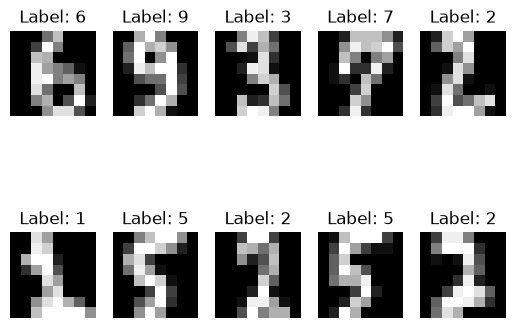

In [13]:
from sklearn.datasets import load_digits
digits = load_digits()

dig = False 
if dig:
    print("####### Dive into the data #######")
    print(digits.data.shape) # look into the shape of the data
    
    print(digits.data) # look into the data roughly
    print(digits.data[0]) # look into the first data
    
    print(digits.target) # look into the target roughly
    print(len(digits.target)) # look into the length of the target
    
    print(type(digits.data)) # look into the type of the data
    print(type(digits.data[0])) # look into the type of the data
    
    print("\n####### Visualize the data #######")

# Visualize the data 
# randomly select 10 images from the dataset and plot them
import matplotlib.pyplot as plt # needed for plotting

import numpy as np
seed = 42
np.random.seed(seed)

indices = np.random.choice(len(digits.data), size=10, replace=False)
print(indices) # look into the indices

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(digits.data[idx].reshape(8, 8), cmap='gray')
    plt.title(f"Label: {digits.target[idx]}")
    plt.axis('off')

- the number of sample is 1797
- "64" is the demention of each data, thus picture is 8 times 8 square
- target is the "label" of each sample
- data type is numpy.ndarray
- 

In [24]:
import umap

# Run UMAP to reduce the dimensionality of the data to 2D
X_reduced = umap.UMAP(n_components=2, random_state=20).fit_transform(digits.data)


/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [23]:
digits.target_names

print(digits.target)
labels = digits.target == 0
print(labels) # look into the boolean array

[0 1 2 ... 8 9 8]
[ True False False ... False False False]


c_plot_bool:  [ True False False ... False False False]
c_plot_bool:  [False  True False ... False False False]
c_plot_bool:  [False False  True ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ...  True False  True]
c_plot_bool:  [False False False ... False  True False]


Text(0, 0.5, 'UMAP 2')

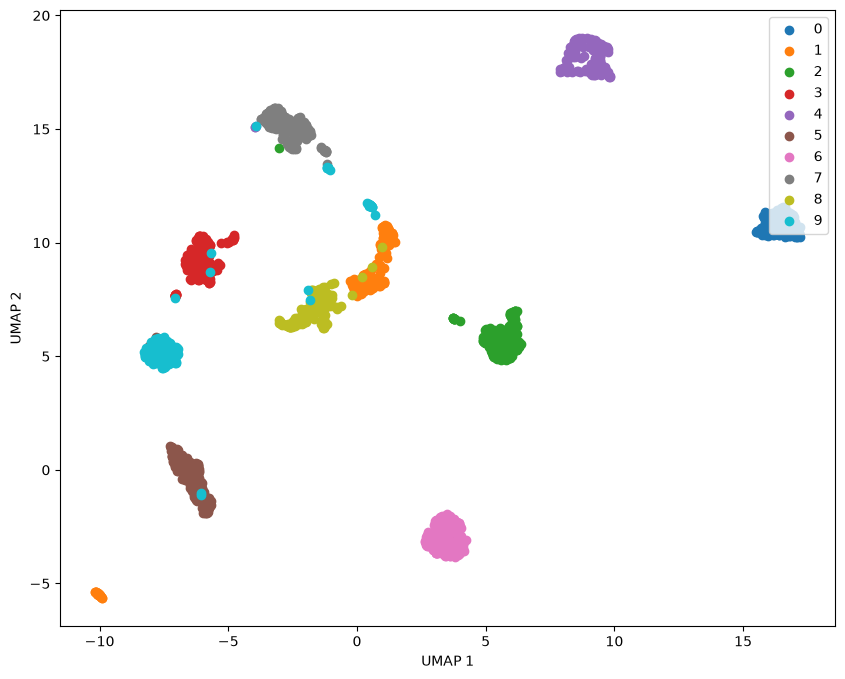

In [25]:
plt.figure(figsize=(10,8))
for each_label in digits.target_names:
    c_plot_bool = digits.target == each_label # 意味？→
    print("c_plot_bool: ", c_plot_bool) # look into the boolean array
    plt.scatter(X_reduced[c_plot_bool,0], X_reduced[c_plot_bool,1], label="{}".format(each_label))

plt.legend(loc="upper right")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

# random states と n_neighborsについて

## ``random states``を変えながら10通り実行する


[1245  220 1518  438 1270  832  692 1309 1101 1742]


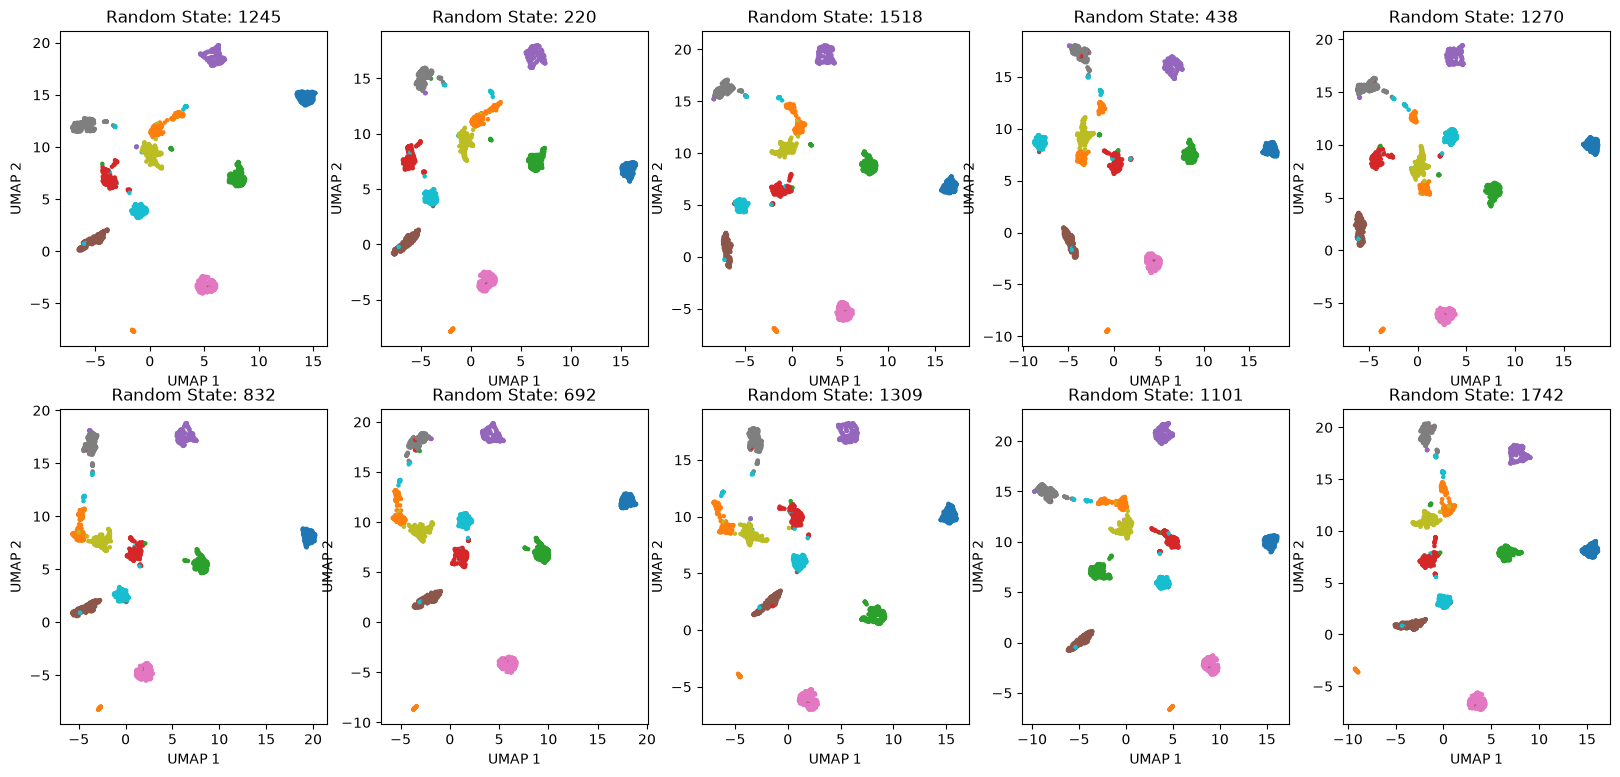

In [35]:
# random states を変えながら10通り
import matplotlib.pyplot as plt # needed for plotting
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="n_jobs value .* overridden")

seed = 42
np.random.seed(seed)

random_states = np.random.choice(len(digits.data), size=10, replace=False)
print(random_states) # look into the random states


X_reduced_list = []
for random_state in random_states:
    X_reduced = umap.UMAP(n_components=2, random_state=random_state).fit_transform(digits.data)
    X_reduced_list.append(X_reduced)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for i, ax in enumerate(axes.flat):
    ax.scatter(X_reduced_list[i][:, 0], X_reduced_list[i][:, 1], c=digits.target, cmap='tab10', s=5)
    ax.set_title(f"Random State: {random_states[i]}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")


##  ``n_neighbors``を変えながら10通り実行する
- 10, 15, 20 くらいがいい？

/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:390: RuntimeWarning: ARPACK has failed, falling back to LOBPCG.
  warnings.warn("ARPACK has failed, falling back to LOBPCG.", RuntimeWarning)
/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:463: UserWarning: Exited at iteration 50 with accuracies 
[2.48955574e-05 5.19663846e-06 1.87311793e-04 5.93252765e-05]
not reaching the requested tolerance 5.9157609939575195e-06.
Use iteration 50 instead with accuracy 
6.918231632157644e-05.

  _, diffusion_map = lobpcg(
/Users/nkn4ryu/ghq/gi

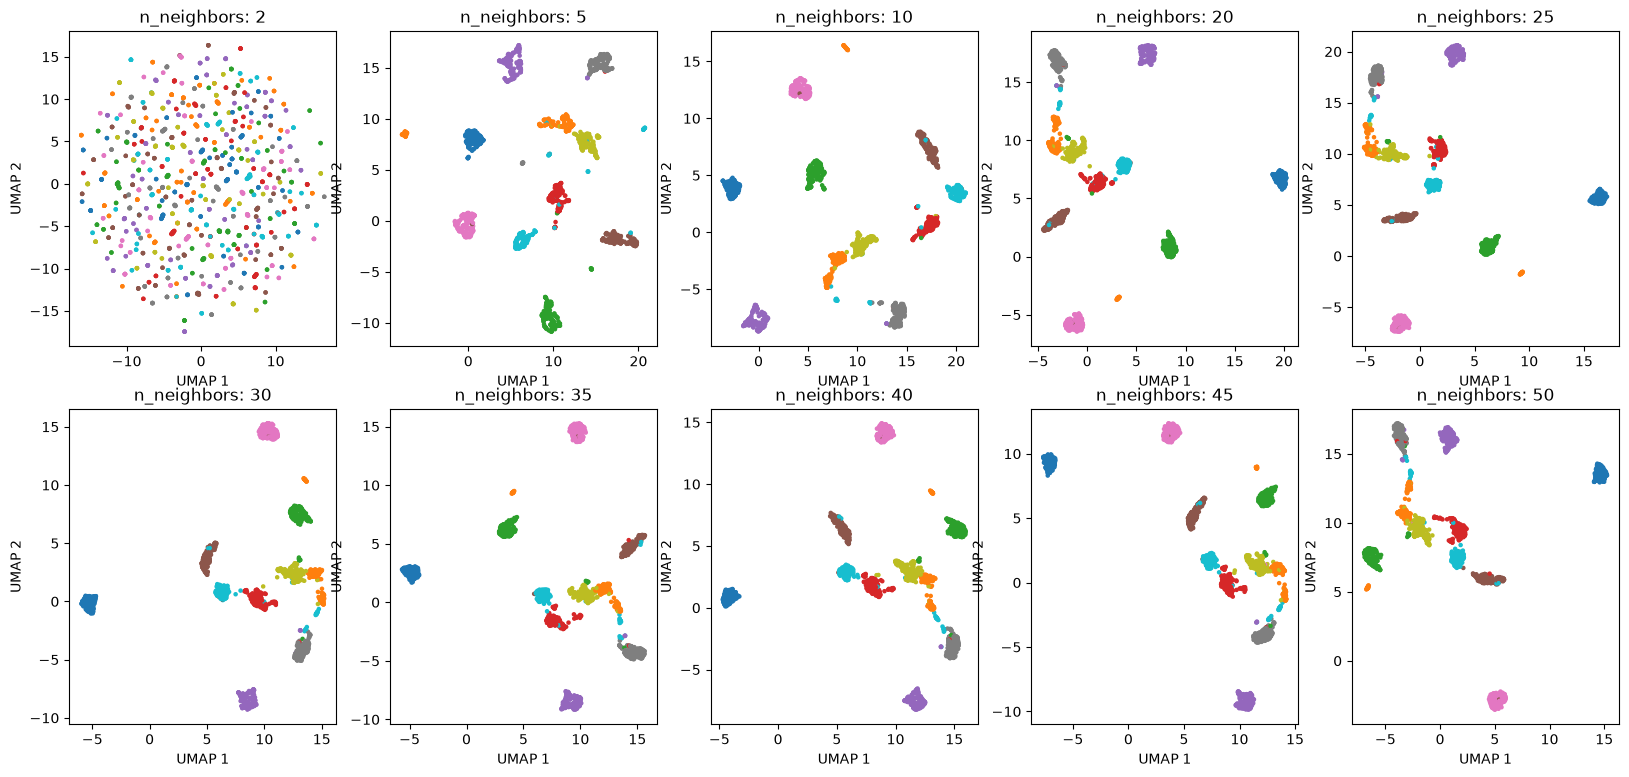

In [37]:
# n_neighbors を変えながら10通り

# random states を変えながら10通り
import matplotlib.pyplot as plt # needed for plotting
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="n_jobs value .* overridden")

seed = 42
np.random.seed(seed)
# n_neighbors を変えながら10通り
n_neighbors_list = [2, 5, 10, 20, 25, 30, 35, 40, 45, 50]


X_reduced_list = []
for n_neighbors in n_neighbors_list:
    X_reduced = umap.UMAP(n_components=2, n_neighbors=n_neighbors).fit_transform(digits.data)
    X_reduced_list.append(X_reduced)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for i, ax in enumerate(axes.flat):
    ax.scatter(X_reduced_list[i][:, 0], X_reduced_list[i][:, 1], c=digits.target, cmap='tab10', s=5)
    ax.set_title(f"n_neighbors: {n_neighbors_list[i]}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
